# **IIC2115 Programación como Herramienta para la Ingeniería**  
### **Capítulo 3: Análisis de datos geoespaciales y redes**
## Cápsula 2: Conceptos Avanzados de Análisis de Redes

**Profesora**: Camila Vera Villa

Esta cápsula continúa donde terminó la anterior. Allá vimos cómo descargar una red, calcular rutas más cortas, integrar datos geoespaciales y visualizar centralidad. Ahora avanzaremos hacia conceptos más complejos que necesitarán para los ejercicios y el laboratorio.

**Contenidos:**
1. Ruta multimodal: construir un grafo de metro y combinarlo con la red peatonal
2. Efecto del buffer en el análisis de una comuna
3. Árbol de Expansión Mínima (MST)
4. Excentricidad y cobertura
5. Flujo máximo y corte mínimo
6. Análisis de vulnerabilidad: remoción de nodos y aristas

---
## 1. Instalación e importación de librerías

Usaremos los mismos datos del curso y continuaremos trabajando con la zona de Macul.

Prmero instalamos librerías necesarias

In [2]:
!pip install osmnx
!pip install geopandas
!pip install networkx

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 104.7/104.7 kB 4.7 MB/s eta 0:00:00


In [3]:
import osmnx as ox
import networkx as nx
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from shapely.geometry import Point
import urllib.request
import os

#### Resolver rutas

In [4]:
# descargar datos solo si no existen
if not os.path.exists("datos_geoespaciales"):
    zip_url = "https://raw.githubusercontent.com/IIC2115/Syllabus/main/Material%20de%20clases/Cap%C3%ADtulo%203/Notebooks/datos_geoespaciales.zip"
    urllib.request.urlretrieve(zip_url, "datos_geoespaciales.zip")
    import zipfile
    with zipfile.ZipFile("datos_geoespaciales.zip", "r") as z:
        z.extractall(".")
    print("datos descargados y extraídos")
else:
    print("datos ya disponibles")

# rutas relativas
comunas = gpd.read_file("datos_geoespaciales/Comunas/comunas.shp")

datos descargados y extraídos


In [5]:
# cargar datos geoespaciales del curso
comunas = gpd.read_file("datos_geoespaciales/Comunas/comunas.shp")
estaciones = gpd.read_file("datos_geoespaciales/Metro 2020/Estaciones_2020/Estaciones_2020.shp")
lineas = gpd.read_file("datos_geoespaciales/Metro 2020/Lineas_2020/Lineas_2020.shp")
accidentes = gpd.read_file("datos_geoespaciales/Accidentes/Puntos_criticos_2019.geojson")

# reproyectar todo a epsg:4326
for gdf in [comunas, estaciones, lineas, accidentes]:
    if gdf.crs != "EPSG:4326":
        gdf = gdf.to_crs("EPSG:4326")

comunas = comunas.to_crs("EPSG:4326")
estaciones = estaciones.to_crs("EPSG:4326")
lineas = lineas.to_crs("EPSG:4326")

---
## 1. Ruta multimodal: caminata + metro

En la cápsula anterior calculamos rutas dentro de una sola red. Pero en la realidad, un viaje puede combinar modos de transporte. Para modelar esto, necesitamos **construir el grafo de la red de metro** a partir de los GeoDataFrames de estaciones y líneas, y luego combinarlo con la red peatonal.

### 1.1 Construir el grafo del metro

In [6]:
# preparar estaciones como nodos
estaciones_metro = estaciones.copy()
estaciones_metro = estaciones_metro.to_crs("EPSG:4326")
estaciones_metro = estaciones_metro.reset_index(drop=True)
estaciones_metro["node_id"] = estaciones_metro.index
estaciones_metro["x"] = estaciones_metro.geometry.x
estaciones_metro["y"] = estaciones_metro.geometry.y
estaciones_metro = estaciones_metro.set_index("node_id")

print(f"estaciones de metro: {len(estaciones_metro)}")
print(estaciones_metro[["x", "y"]].head())

estaciones de metro: 127
                 x          y
node_id                      
0       -70.661415 -33.526515
1       -70.668550 -33.439158
2       -70.680303 -33.440437
3       -70.643178 -33.541225
4       -70.634094 -33.542453


In [7]:
# preparar líneas como aristas
lineas_metro = lineas.copy()
lineas_metro = lineas_metro.to_crs("EPSG:4326")

def nearest_node(point):
    return estaciones_metro.geometry.distance(point).idxmin()

lineas_metro = lineas_metro.reset_index(drop=True)
lineas_metro["u"] = lineas_metro.geometry.apply(
    lambda g: nearest_node(Point(g.coords[0])))
lineas_metro["v"] = lineas_metro.geometry.apply(
    lambda g: nearest_node(Point(g.coords[-1])))

# establecer índice múltiple (u, v, key) — requerido por osmnx
lineas_metro["key"] = 0
lineas_metro.set_index(["u", "v", "key"], inplace=True)
lineas_metro["length"] = lineas_metro.geometry.length

print(f"tramos de metro: {len(lineas_metro)}")

/tmp/ipykernel_1959/2671842392.py:6: UserWarning: Geometry is in a geographic CRS. Results from 'distance' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  return estaciones_metro.geometry.distance(point).idxmin()
/tmp/ipykernel_1959/2671842392.py:6: UserWarning: Geometry is in a geographic CRS. Results from 'distance' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  return estaciones_metro.geometry.distance(point).idxmin()
/tmp/ipykernel_1959/2671842392.py:6: UserWarning: Geometry is in a geographic CRS. Results from 'distance' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  return estaciones_metro.geometry.distance(point).idxmin()
/tmp/ipykernel_1959/2671842392.py:6: UserWarning: Geometry is in a geographic CRS. Results from 'distance' are likely incorrect. Use 'GeoSeries.to_crs()' 

tramos de metro: 137


/tmp/ipykernel_1959/2671842392.py:6: UserWarning: Geometry is in a geographic CRS. Results from 'distance' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  return estaciones_metro.geometry.distance(point).idxmin()
/tmp/ipykernel_1959/2671842392.py:6: UserWarning: Geometry is in a geographic CRS. Results from 'distance' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  return estaciones_metro.geometry.distance(point).idxmin()
/tmp/ipykernel_1959/2671842392.py:6: UserWarning: Geometry is in a geographic CRS. Results from 'distance' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  return estaciones_metro.geometry.distance(point).idxmin()
/tmp/ipykernel_1959/2671842392.py:6: UserWarning: Geometry is in a geographic CRS. Results from 'distance' are likely incorrect. Use 'GeoSeries.to_crs()' 

### 1.2 Definir origen y destino

Vamos a calcular una ruta multimodal desde el **Campus San Joaquín** hasta la **estación de metro más cercana al centroide de Providencia**.

In [8]:
# origen: campus san joaquín (aprox)
origen = (-33.4983, -70.6134)

# destino: centroide de providencia
providencia = comunas[comunas["Comuna"] == "Providencia"].to_crs("EPSG:32719")
centroide_prov = providencia.geometry.centroid.iloc[0]
centroide_prov = gpd.GeoSeries([centroide_prov], crs="EPSG:32719").to_crs("EPSG:4326").iloc[0]

# encontrar estación de metro más cercana al centroide
dist_a_centroide = estaciones_metro.geometry.distance(centroide_prov)
estacion_destino = dist_a_centroide.idxmin()
coord_destino = (estaciones_metro.loc[estacion_destino].y,
                 estaciones_metro.loc[estacion_destino].x)

print(f"destino: estación #{estacion_destino} en ({coord_destino[0]:.4f}, {coord_destino[1]:.4f})")

destino: estación #72 en (-33.4255, -70.6138)


/tmp/ipykernel_1959/3345392153.py:10: UserWarning: Geometry is in a geographic CRS. Results from 'distance' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  dist_a_centroide = estaciones_metro.geometry.distance(centroide_prov)


### 1.3 Descargar red peatonal y calcular tramos

In [9]:
# descargar red peatonal para macul y providencia
grafo_walk = ox.graph_from_place(
    ["Macul, Santiago, Chile", "Providencia, Santiago, Chile"],
    network_type="walk"
)
print(f"red peatonal - nodos: {grafo_walk.number_of_nodes()}")

red peatonal - nodos: 6676


In [10]:
# tramo 1: caminar desde origen hasta estación de metro más cercana al origen
nodo_origen = ox.nearest_nodes(grafo_walk, X=origen[1], Y=origen[0])

# encontrar estación de metro más cercana al origen
dist_a_origen = estaciones_metro.geometry.distance(Point(origen[1], origen[0]))
estacion_origen = dist_a_origen.idxmin()
coord_estacion_origen = (estaciones_metro.loc[estacion_origen].y,
                         estaciones_metro.loc[estacion_origen].x)
nodo_estacion_origen = ox.nearest_nodes(grafo_walk,
                                         X=coord_estacion_origen[1],
                                         Y=coord_estacion_origen[0])

# ruta caminando al metro
ruta_caminar_1 = nx.shortest_path(grafo_walk, nodo_origen, nodo_estacion_origen, weight="length")
largo_caminar_1 = nx.shortest_path_length(grafo_walk, nodo_origen, nodo_estacion_origen, weight="length")
print(f"caminata al metro: {largo_caminar_1:.0f} m")

caminata al metro: 0 m


/tmp/ipykernel_1959/2656064657.py:5: UserWarning: Geometry is in a geographic CRS. Results from 'distance' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  dist_a_origen = estaciones_metro.geometry.distance(Point(origen[1], origen[0]))


In [11]:
# tramo 2: metro (usamos el grafo de metro)
# necesitamos encontrar la ruta en metro entre estación origen y destino
grafo_metro = nx.MultiDiGraph()
for idx, row in estaciones_metro.iterrows():
    grafo_metro.add_node(idx, x=row.x, y=row.y)
for (u, v, k), row in lineas_metro.iterrows():
    grafo_metro.add_edge(u, v, key=k, length=row.length)
    grafo_metro.add_edge(v, u, key=k, length=row.length)  # bidireccional

try:
    ruta_metro = nx.shortest_path(grafo_metro, estacion_origen, estacion_destino, weight="length")
    largo_metro = nx.shortest_path_length(grafo_metro, estacion_origen, estacion_destino, weight="length")
    print(f"tramo metro: {largo_metro:.0f} m, {len(ruta_metro)} estaciones")
except nx.NetworkXNoPath:
    print("no hay ruta en metro entre estas estaciones")

tramo metro: 0 m, 12 estaciones


In [12]:
# tramo 3: caminar desde estación destino hasta el centroide
nodo_estacion_destino = ox.nearest_nodes(grafo_walk,
                                          X=coord_destino[1],
                                          Y=coord_destino[0])
nodo_destino_final = ox.nearest_nodes(grafo_walk,
                                       X=centroide_prov.x,
                                       Y=centroide_prov.y)

ruta_caminar_2 = nx.shortest_path(grafo_walk, nodo_estacion_destino, nodo_destino_final, weight="length")
largo_caminar_2 = nx.shortest_path_length(grafo_walk, nodo_estacion_destino, nodo_destino_final, weight="length")
print(f"caminata final: {largo_caminar_2:.0f} m")

caminata final: 684 m


In [13]:
# estimar tiempo total
vel_caminar = 5  # km/h
vel_metro = 35   # km/h

t_caminar = (largo_caminar_1 + largo_caminar_2) / 1000 / vel_caminar * 60  # minutos
t_metro = largo_metro / 1000 / vel_metro * 60  # minutos
t_total = t_caminar + t_metro

print(f"tiempo caminando: {t_caminar:.1f} min")
print(f"tiempo en metro: {t_metro:.1f} min")
print(f"tiempo total: {t_total:.1f} min")

tiempo caminando: 8.2 min
tiempo en metro: 0.0 min
tiempo total: 8.2 min



## 2. Efecto del buffer en el análisis de una comuna

Cuando analizamos la red de una sola comuna, los nodos del borde tienen centralidad artificialmente baja porque la red está cortada ahí. Una solución es agregar un **buffer** alrededor de la comuna para capturar la red circundante.

In [14]:
# descargar red de macul
grafo_macul = ox.graph_from_place("Macul, Santiago, Chile", network_type="drive")

# calcular betweenness sin buffer
bc_sin_buffer = nx.betweenness_centrality(grafo_macul, weight="length")

print(f"red macul - nodos: {grafo_macul.number_of_nodes()}")

red macul - nodos: 2188


Ojo con los tiempos de ejecución, esta celda tarda 30min aprox

In [15]:
# crear polígono de macul con buffer de 2 km
macul = comunas[comunas["Comuna"] == "Macul"].to_crs("EPSG:32719")
macul_buffer = macul.geometry.buffer(2000).to_crs("EPSG:4326").iloc[0]

# descargar red del área con buffer
grafo_buffer = ox.graph_from_polygon(macul_buffer, network_type="drive")

# calcular betweenness con buffer
bc_con_buffer = nx.betweenness_centrality(grafo_buffer, weight="length")

print(f"red con buffer - nodos: {grafo_buffer.number_of_nodes()}")

red con buffer - nodos: 10373


/tmp/ipykernel_1959/3558812406.py:10: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap_sin = cm.get_cmap("YlOrRd")
/tmp/ipykernel_1959/3558812406.py:22: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap_con = cm.get_cmap("YlOrRd")


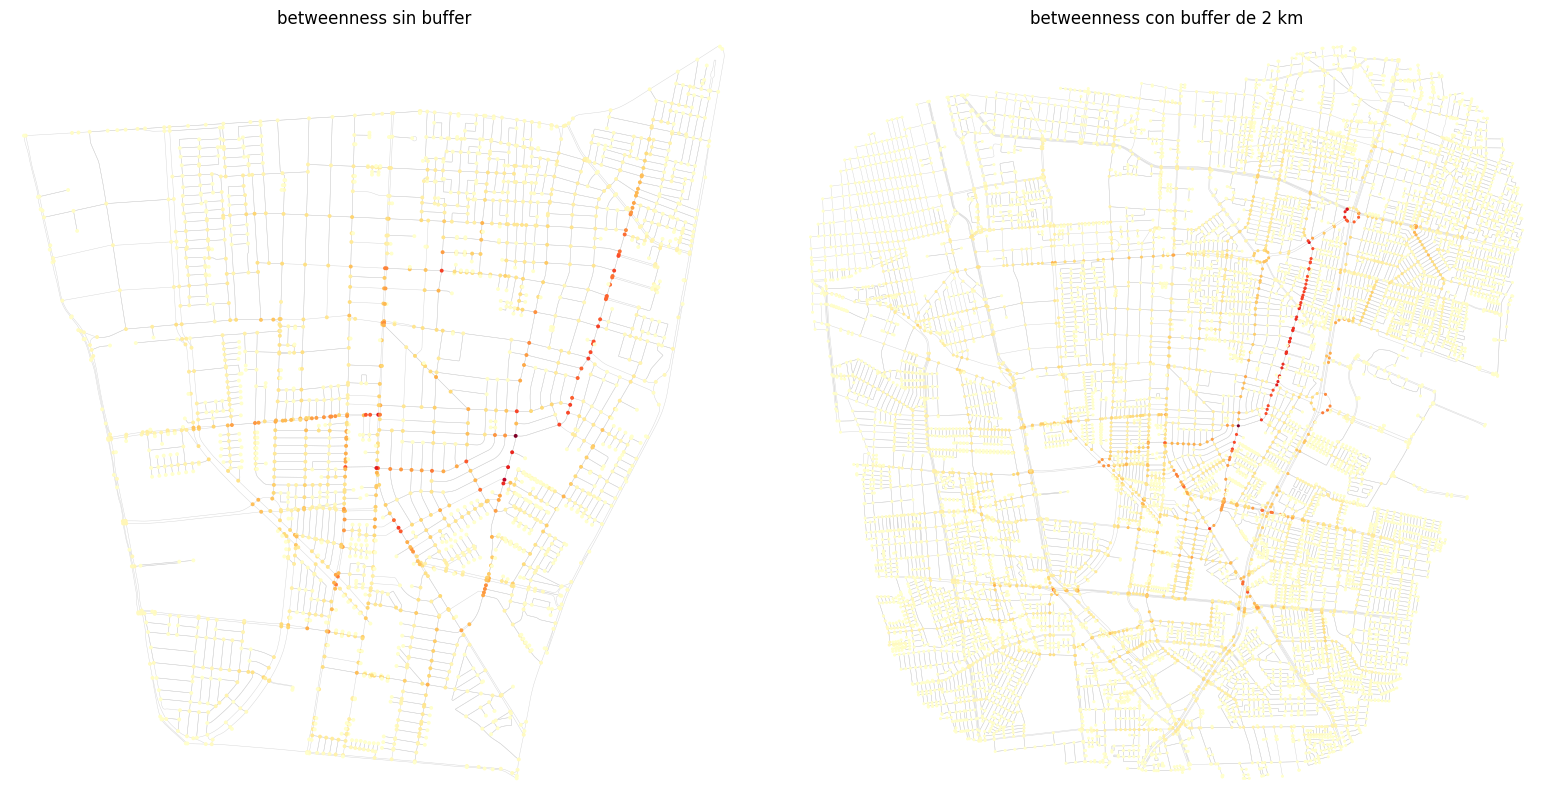

In [16]:
import matplotlib.colors as mcolors
import matplotlib.cm as cm

# comparar visualmente
fig, axes = plt.subplots(1, 2, figsize=(16, 8))

# preparar mapa de colores para sin buffer
nc_sin_vals = [bc_sin_buffer.get(n, 0) for n in grafo_macul.nodes()]
norm_sin = mcolors.Normalize(vmin=min(nc_sin_vals), vmax=max(nc_sin_vals))
cmap_sin = cm.get_cmap("YlOrRd")
nc_sin_colors = [cmap_sin(norm_sin(val)) for val in nc_sin_vals]

# sin buffer
ox.plot_graph(grafo_macul, node_size=8, node_color=nc_sin_colors,
              edge_color="lightgray", edge_linewidth=0.3,
              ax=axes[0], show=False, close=False)
axes[0].set_title("betweenness sin buffer", fontsize=12)

# preparar mapa de colores para con buffer
nc_con_vals = [bc_con_buffer.get(n, 0) for n in grafo_buffer.nodes()]
norm_con = mcolors.Normalize(vmin=min(nc_con_vals), vmax=max(nc_con_vals))
cmap_con = cm.get_cmap("YlOrRd")
nc_con_colors = [cmap_con(norm_con(val)) for val in nc_con_vals]

# con buffer
ox.plot_graph(grafo_buffer, node_size=5, node_color=nc_con_colors,
              edge_color="lightgray", edge_linewidth=0.3,
              ax=axes[1], show=False, close=False)
axes[1].set_title("betweenness con buffer de 2 km", fontsize=12)

plt.tight_layout()
plt.show()

Observen cómo los nodos de borde cambian su centralidad. Con buffer, los nodos que realmente son importantes para la red metropolitana se destacan mejor. Sin buffer, el análisis está sesgado por los bordes artificiales de la comuna.


## 3. Árbol de Expansión Mínima (MST)

Un MST conecta todos los nodos de un grafo sin ciclos y con el menor peso total posible. Es útil para encontrar la red mínima que conecta un conjunto de puntos.

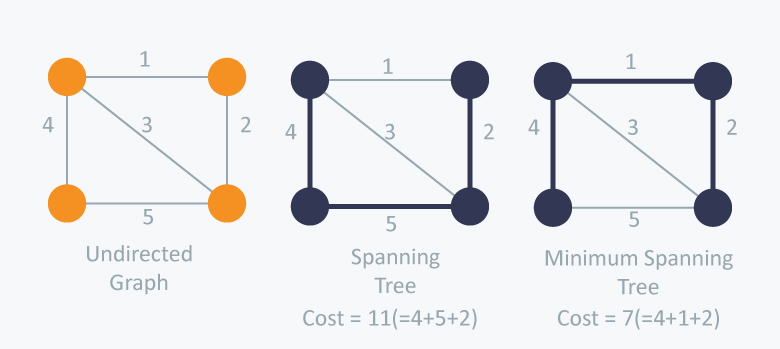

El costo del árbol de expansión es la suma de los pesos de todas las aristas del árbol.

--> El árbol de expansión mínimo es aquel cuyo costo es mínimo entre todos los árboles de expansión.


 fuente: https://www.hackerearth.com/practice/algorithms/graphs/minimum-spanning-tree/tutorial/


Vamos a seleccionar 4 puntos de interés en Macul y encontrar el MST que los conecta.

In [17]:
# definir 4 puntos de interés en macul
puntos = {
    "campus_sjq": (-33.4983, -70.6134),
    "plaza_macul": (-33.4895, -70.6015),
    "hospital": (-33.5100, -70.6050),
    "estadio": (-33.4700, -70.6000),
}

# encontrar nodos más cercanos en la red
nodos_poi = {}
for nombre, (lat, lon) in puntos.items():
    nodos_poi[nombre] = ox.nearest_nodes(grafo_macul, X=lon, Y=lat)
    print(f"{nombre}: nodo {nodos_poi[nombre]}")

campus_sjq: nodo 6996797191
plaza_macul: nodo 516811856
hospital: nodo 11571097732
estadio: nodo 605182028


In [18]:
# construir grafo completo ponderado entre los 4 puntos
# peso = distancia de ruta más corta en la red real
nombres = list(nodos_poi.keys())
grafo_completo = nx.Graph()

for i, n1 in enumerate(nombres):
    for j, n2 in enumerate(nombres):
        if i < j:
            try:
                dist = nx.shortest_path_length(grafo_macul,
                                                nodos_poi[n1],
                                                nodos_poi[n2],
                                                weight="length")
                grafo_completo.add_edge(n1, n2, weight=dist)
                print(f"{n1} <-> {n2}: {dist:.0f} m")
            except nx.NetworkXNoPath:
                print(f"{n1} <-> {n2}: sin ruta")

print(f"\ngrafo completo: {grafo_completo.number_of_edges()} aristas")

campus_sjq <-> plaza_macul: 2503 m
campus_sjq <-> hospital: 2491 m
campus_sjq <-> estadio: 4425 m
plaza_macul <-> hospital: 2148 m
plaza_macul <-> estadio: 1926 m
hospital <-> estadio: sin ruta

grafo completo: 5 aristas


In [19]:
# obtener el mst
mst = nx.minimum_spanning_tree(grafo_completo, weight="weight")

print("aristas del mst:")
peso_total = 0
for u, v, data in mst.edges(data=True):
    print(f"  {u} <-> {v}: {data["weight"]:.0f} m")
    peso_total += data["weight"]

peso_completo = sum(d["weight"] for _, _, d in grafo_completo.edges(data=True))
print(f"\npeso total mst: {peso_total:.0f} m")
print(f"peso total grafo completo: {peso_completo:.0f} m")
print(f"ahorro: {(1 - peso_total/peso_completo)*100:.1f}%")

aristas del mst:
  campus_sjq <-> hospital: 2491 m
  plaza_macul <-> estadio: 1926 m
  plaza_macul <-> hospital: 2148 m

peso total mst: 6566 m
peso total grafo completo: 13494 m
ahorro: 51.3%


El MST nos da la forma más eficiente de conectar todos los puntos, pero sin redundancia. Si una arista del MST se corta, el grafo se desconecta. En el grafo completo hay rutas alternativas pero con mayor costo total.


## 4. Excentricidad y cobertura

La **excentricidad** de un nodo es la distancia máxima desde ese nodo a cualquier otro en el grafo. Es útil para evaluar la **cobertura** de un punto: un nodo con baja excentricidad llega rápido a cualquier parte de la red.

In [20]:
# la excentricidad requiere un grafo fuertemente conexo
# trabajamos con el componente conexo más grande
if nx.is_strongly_connected(grafo_macul):
    subgrafo = grafo_macul
else:
    nodos_comp = max(nx.strongly_connected_components(grafo_macul), key=len)
    subgrafo = grafo_macul.subgraph(nodos_comp).copy()
    print(f"usando componente más grande: {subgrafo.number_of_nodes()} nodos "
          f"(de {grafo_macul.number_of_nodes()} totales)")

usando componente más grande: 2184 nodos (de 2188 totales)


In [21]:
# calcular excentricidad para los puntos de interés
for nombre, nodo in nodos_poi.items():
    if nodo in subgrafo:
        ecc = nx.eccentricity(subgrafo, v=nodo, weight="length")
        print(f"{nombre}: excentricidad = {ecc:.0f} m ({ecc/1000:.1f} km)")
    else:
        print(f"{nombre}: fuera del componente conexo")

campus_sjq: excentricidad = 6810 m (6.8 km)
plaza_macul: excentricidad = 4623 m (4.6 km)
hospital: fuera del componente conexo
estadio: excentricidad = 5001 m (5.0 km)


El punto con **menor excentricidad** es el que tiene mejor cobertura — en el peor caso, está más cerca de cualquier parte de la red. Es un criterio útil para decidir dónde ubicar servicios de emergencia.


## 5. Flujo máximo y corte mínimo

Estos conceptos permiten analizar la **capacidad** de una red para transportar flujo (vehículos, personas) entre un origen y un destino.

- **Flujo máximo**: la mayor cantidad de flujo que puede pasar del origen al destino respetando las capacidades.
- **Corte mínimo**: el conjunto de aristas cuya remoción desconecta el origen del destino con el menor costo total.

Para esto necesitamos una red con **atributos de capacidad**. Vamos a crear una red simplificada entre comunas.

In [22]:
# crear una red simplificada entre 4 comunas
# usamos las distancias de ruta más corta como proxy inverso de capacidad
# Corregido: Se agregaron los caracteres especiales y tildes correspondientes (Ñuñoa y Peñalolén)
comunas_ejemplo = ["Macul", "Ñuñoa", "Peñalolén", "La Florida"]

# obtener centroides de las comunas
centroides = {}
for nombre in comunas_ejemplo:
    com = comunas[comunas["Comuna"] == nombre].to_crs("EPSG:32719")
    c = com.geometry.centroid.iloc[0]
    c_4326 = gpd.GeoSeries([c], crs="EPSG:32719").to_crs("EPSG:4326").iloc[0]
    centroides[nombre] = (c_4326.y, c_4326.x)
    print(f"{nombre}: ({c_4326.y:.4f}, {c_4326.x:.4f})")

Macul: (-33.4894, -70.6000)
Ñuñoa: (-33.4578, -70.5987)
Peñalolén: (-33.4854, -70.5253)
La Florida: (-33.5283, -70.5398)


In [23]:
# descargar red vehicular del sector
grafo_sector = ox.graph_from_place(
    [f"{c}, Santiago, Chile" for c in ["Macul", "Ñuñoa", "Peñalolén", "La Florida"]],
    network_type="drive"
)
print(f"red del sector: {grafo_sector.number_of_nodes()} nodos")

red del sector: 17739 nodos


In [24]:
# construir red simplificada con capacidades
# la capacidad es inversamente proporcional a la distancia
# (calles más cortas entre comunas = mayor capacidad de conexión)
red_simple = nx.DiGraph()

nodos_comunas = {}
for nombre, (lat, lon) in centroides.items():
    nodos_comunas[nombre] = ox.nearest_nodes(grafo_sector, X=lon, Y=lat)

for i, c1 in enumerate(comunas_ejemplo):
    for j, c2 in enumerate(comunas_ejemplo):
        if i != j:
            try:
                dist = nx.shortest_path_length(grafo_sector,
                                                nodos_comunas[c1],
                                                nodos_comunas[c2],
                                                weight="length")
                # capacidad: normalizada inversamente a la distancia
                capacidad = int(10000 / (dist / 1000))  # unidades arbitrarias
                red_simple.add_edge(c1, c2, capacity=capacidad)
            except nx.NetworkXNoPath:
                pass

print("aristas con capacidad:")
for u, v, d in red_simple.edges(data=True):
    print(f"  {u} -> {v}: capacidad = {d['capacity']}")

aristas con capacidad:
  Macul -> Ñuñoa: capacidad = 2624
  Macul -> Peñalolén: capacidad = 1103
  Macul -> La Florida: capacidad = 1195
  Ñuñoa -> Macul: capacidad = 2808
  Ñuñoa -> Peñalolén: capacidad = 1203
  Ñuñoa -> La Florida: capacidad = 838
  Peñalolén -> Macul: capacidad = 1069
  Peñalolén -> Ñuñoa: capacidad = 1201
  Peñalolén -> La Florida: capacidad = 1362
  La Florida -> Macul: capacidad = 1147
  La Florida -> Ñuñoa: capacidad = 839
  La Florida -> Peñalolén: capacidad = 1361


In [25]:
# calcular flujo máximo entre macul y la florida
flujo_valor, flujo_dict = nx.maximum_flow(red_simple, "Macul", "La Florida")
print(f"flujo máximo MACUL -> LA FLORIDA: {flujo_valor}")
print(f"\ndistribución del flujo:")
for origen, destinos in flujo_dict.items():
    for destino, flujo in destinos.items():
        if flujo > 0:
            print(f"  {origen} -> {destino}: {flujo}")

flujo máximo MACUL -> LA FLORIDA: 3395

distribución del flujo:
  Macul -> Ñuñoa: 2041
  Macul -> Peñalolén: 159
  Macul -> La Florida: 1195
  Ñuñoa -> Peñalolén: 1203
  Ñuñoa -> La Florida: 838
  Peñalolén -> La Florida: 1362


In [26]:
# calcular corte mínimo
corte_valor, (conjunto_s, conjunto_t) = nx.minimum_cut(red_simple, "Macul", "La Florida")
print(f"valor del corte mínimo: {corte_valor}")
print(f"conjunto S (lado origen): {conjunto_s}")
print(f"conjunto T (lado destino): {conjunto_t}")

# identificar aristas del corte
print("\naristas del corte mínimo:")
for u in conjunto_s:
    for v in conjunto_t:
        if red_simple.has_edge(u, v):
            cap = red_simple[u][v]["capacity"]
            print(f"  {u} -> {v}: capacidad = {cap}")

valor del corte mínimo: 3395
conjunto S (lado origen): {'Macul', 'Ñuñoa', 'Peñalolén'}
conjunto T (lado destino): {'La Florida'}

aristas del corte mínimo:
  Macul -> La Florida: capacidad = 1195
  Ñuñoa -> La Florida: capacidad = 838
  Peñalolén -> La Florida: capacidad = 1362


Las aristas del corte mínimo son los **cuellos de botella** — si se bloquean, el flujo entre origen y destino se interrumpe completamente. Son candidatas prioritarias para intervención o refuerzo.

---
## 6. Análisis de vulnerabilidad

Finalmente, podemos evaluar la **vulnerabilidad** de la red eliminando nodos o aristas y midiendo cómo cambia la conectividad.

In [27]:
# usamos la red de macul
# calcular métricas base
n_componentes_base = nx.number_strongly_connected_components(grafo_macul)
nodos_comp_mas_grande = len(max(nx.strongly_connected_components(grafo_macul), key=len))

print(f"estado base:")
print(f"  componentes conexos: {n_componentes_base}")
print(f"  nodos en componente más grande: {nodos_comp_mas_grande}")

estado base:
  componentes conexos: 5
  nodos en componente más grande: 2184


In [28]:
# identificar los 5 nodos con mayor betweenness
bc = nx.betweenness_centrality(grafo_macul, weight="length")
top_5 = sorted(bc, key=bc.get, reverse=True)[:5]

print("top 5 nodos por betweenness:")
for nodo in top_5:
    print(f"  nodo {nodo}: betweenness = {bc[nodo]:.6f}")

top 5 nodos por betweenness:
  nodo 276284077: betweenness = 0.156044
  nodo 276282459: betweenness = 0.135122
  nodo 515257831: betweenness = 0.119383
  nodo 12920644355: betweenness = 0.118188
  nodo 276282913: betweenness = 0.114904


In [29]:
# simular remoción secuencial de los nodos más críticos
print(f"{"nodos removidos":>20s} | {"componentes":>12s} | {"mayor comp.":>12s} | {"% pérdida":>10s}")
print("-" * 65)

grafo_test = grafo_macul.copy()
for i, nodo in enumerate(top_5):
    grafo_test.remove_node(nodo)
    n_comp = nx.number_strongly_connected_components(grafo_test)
    mayor = len(max(nx.strongly_connected_components(grafo_test), key=len))
    perdida = (1 - mayor / nodos_comp_mas_grande) * 100
    print(f"{i+1:>20d} | {n_comp:>12d} | {mayor:>12d} | {perdida:>9.1f}%")

     nodos removidos |  componentes |  mayor comp. |  % pérdida
-----------------------------------------------------------------
                   1 |            5 |         2183 |       0.0%
                   2 |            5 |         2182 |       0.1%
                   3 |            5 |         2181 |       0.1%
                   4 |            6 |         2179 |       0.2%
                   5 |            7 |         2176 |       0.4%


Cada fila muestra qué pasa cuando removemos un nodo más. Si la pérdida del componente más grande crece rápidamente, la red es **vulnerable** — depende de pocos nodos para su conectividad. Si crece lentamente, es **resiliente**.

---
## Resumen

En esta segunda cápsula cubrimos los conceptos avanzados que necesitarán para los ejercicios y el laboratorio:

- **Ruta multimodal**: construir el grafo de metro desde GeoDataFrames y combinar tramos de distinto modo.
- **Buffer**: cómo el recorte de la red afecta las métricas de centralidad y cómo corregirlo.
- **MST**: encontrar la conexión mínima entre un conjunto de puntos estratégicos.
- **Excentricidad**: evaluar la cobertura territorial de un nodo como peor caso de accesibilidad.
- **Flujo máximo y corte mínimo**: analizar capacidad de la red e identificar cuellos de botella.
- **Vulnerabilidad**: medir el impacto de remover nodos críticos en la conectividad global.

Con estas herramientas están preparados para abordar todas las misiones de los ejercicios formativos.